# Evaluación Formativa 2 — Modelamiento predictivo (actualizada)

**Curso:** MCDI501 — Estadística Computacional para la Toma de Decisiones  
**Proyecto:** *Online Shoppers Purchasing Intention*  
**Integrantes:** Verónica Durán Cisterna · Raúl Moya Arriagada · Daniela Rojas Vilches · Manuel Sánchez Cárcamo  
**Docente:** Dr. Jean Paul Maidana González

## Objetivo
Integrar S1 y S2 en un primer modelo de regresión logística. Como el dataset original está completo, esta versión incorpora la instrucción complementaria del curso: generar faltantes **MCAR** controlados en variables numéricas, conservar los valores originales e imputar por **mediana** en F2.

> **Pregunta:** ¿Qué características del comportamiento de navegación de los usuarios se relacionan con la probabilidad de que una sesión de comercio electrónico termine en una compra?

El alcance es asociativo, no causal.

## 1. Librerías y reproducibilidad

Se utiliza `RANDOM_STATE = 42`. La misma semilla hace reproducibles tanto los faltantes MCAR como la partición 70/30.

In [1]:
from pathlib import Path
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import statsmodels.api as sm

from statsmodels.stats.outliers_influence import variance_inflation_factor
from sklearn.compose import ColumnTransformer
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.metrics import (
    confusion_matrix, ConfusionMatrixDisplay, accuracy_score,
    precision_score, recall_score, f1_score, classification_report,
    roc_curve, roc_auc_score, mean_absolute_error, mean_squared_error
)

warnings.filterwarnings("ignore")
RANDOM_STATE = 42
MISSING_RATE = 0.12
np.random.seed(RANDOM_STATE)

print("Semilla:", RANDOM_STATE)
print("MCAR planificado:", f"{MISSING_RATE:.0%}")

Semilla: 42
MCAR planificado: 12%


## 2. Carga y verificación del dataset original

S1 verificó que la base original contiene **12.330 sesiones y 18 variables, sin valores faltantes**. Los faltantes introducidos más adelante son artificiales y se generan únicamente para desarrollar el ejercicio metodológico.

In [2]:
candidatos = [
    Path("data/raw/online_shoppers_intention.csv"),
    Path("../data/raw/online_shoppers_intention.csv"),
    Path("../../data/raw/online_shoppers_intention.csv"),
]
DATA_PATH = next((p for p in candidatos if p.exists()), None)
if DATA_PATH is None:
    raise FileNotFoundError("No se encontró data/raw/online_shoppers_intention.csv")

df_original = pd.read_csv(DATA_PATH)
print("Archivo:", DATA_PATH.resolve())
print("Dimensiones:", df_original.shape)
print("Faltantes originales:", int(df_original.isna().sum().sum()))
display(df_original.head())

assert df_original.shape == (12330, 18)
assert df_original.isna().sum().sum() == 0

Archivo: C:\Users\eliza\Desktop\ESTUDIOS\MAGÍSTER\2 ESTADÍSITICAS COMPUTACIONAL\Proyecto Estadística\Online-Shoppers-Purchasing-Intention\data\raw\online_shoppers_intention.csv
Dimensiones: (12330, 18)
Faltantes originales: 0


,Administrative,Administrative_Duration,Informational,Informational_Duration,ProductRelated,ProductRelated_Duration,BounceRates,ExitRates,PageValues,SpecialDay,Month,OperatingSystems,Browser,Region,TrafficType,VisitorType,Weekend,Revenue
0,0,0.0,0,0.0,1,0.000000,0.20,0.20,0.0,0.0,Feb,1,1,1,1,Returning_Visitor,False,False
1,0,0.0,0,0.0,2,64.000000,0.00,0.10,0.0,0.0,Feb,2,2,1,2,Returning_Visitor,False,False
2,0,0.0,0,0.0,1,0.000000,0.20,0.20,0.0,0.0,Feb,4,1,9,3,Returning_Visitor,False,False
3,0,0.0,0,0.0,2,2.666667,0.05,0.14,0.0,0.0,Feb,3,2,2,4,Returning_Visitor,False,False
4,0,0.0,0,0.0,10,627.500000,0.02,0.05,0.0,0.0,Feb,3,3,1,4,Returning_Visitor,True,False


## 3. Evidencia previa S1 → S2 → F2

No se repiten los análisis previos; se usan para decidir.

- `Revenue` está desbalanceada: aproximadamente 15,5 % de sesiones terminan en compra.
- `PageValues` mostró una asociación especialmente fuerte con `Revenue`.
- `VisitorType` presentó asociación significativa, aunque pequeña.
- S2 confirmó correlaciones estables: `BounceRates`–`ExitRates` ≈ 0,913 y `ProductRelated`–`ProductRelated_Duration` ≈ 0,861.
- También se validaron `Informational`–`Informational_Duration` ≈ 0,619 y `Administrative`–`Administrative_Duration` ≈ 0,602.
- Los valores extremos no se eliminan automáticamente: S2 mostró sensibilidad global, pero el jackknife no identificó una única observación dominante.

## 4. Generación controlada de faltantes MCAR

Se seleccionan `ProductRelated_Duration` y `ExitRates` porque son numéricas, relevantes y poseen correlaciones claras y estables con otras variables según S1/S2.

Se oculta exactamente **12 %** de cada variable de manera completamente aleatoria (**MCAR**) y reproducible. `Revenue` no se modifica. Antes de introducir `NaN`, se conservan los valores verdaderos para evaluar imputaciones en S3.

In [3]:
VARIABLES_MCAR = ["ProductRelated_Duration", "ExitRates"]
df = df_original.copy()
valores_originales_mcar = df_original[VARIABLES_MCAR].copy()
indices_mcar = {}

for i, variable in enumerate(VARIABLES_MCAR):
    rng = np.random.default_rng(RANDOM_STATE + i)
    n_missing = round(MISSING_RATE * len(df))
    idx = rng.choice(df.index.to_numpy(), size=n_missing, replace=False)
    indices_mcar[variable] = idx
    df.loc[idx, variable] = np.nan

resumen_mcar = pd.DataFrame({
    "Variable": VARIABLES_MCAR,
    "Faltantes_generados": [df[v].isna().sum() for v in VARIABLES_MCAR],
    "Porcentaje": [100*df[v].isna().mean() for v in VARIABLES_MCAR]
})
display(resumen_mcar.round(2))
print("Faltantes en Revenue:", df["Revenue"].isna().sum())

,Variable,Faltantes_generados,Porcentaje
0,ProductRelated_Duration,1480,12.0
1,ExitRates,1480,12.0


Faltantes en Revenue: 0


## 5. Partición 70/30 estratificada

La máscara MCAR se genera antes de la partición. Luego se divide 70/30 estratificando por `Revenue`, preservando la tasa de compra.

In [4]:
y = df["Revenue"].astype(int)
X = df.drop(columns="Revenue")

X_train_full, X_test_full, y_train, y_test = train_test_split(
    X, y, test_size=0.30, random_state=RANDOM_STATE, stratify=y
)

print("Train:", X_train_full.shape, "| compra:", f"{y_train.mean():.2%}")
print("Test :", X_test_full.shape, "| compra:", f"{y_test.mean():.2%}")
display(pd.DataFrame({
    "Train": X_train_full[VARIABLES_MCAR].isna().sum(),
    "Test": X_test_full[VARIABLES_MCAR].isna().sum()
}))

Train: (8631, 17) | compra: 15.48%
Test : (3699, 17) | compra: 15.46%


,Train,Test
ProductRelated_Duration,1030,450
ExitRates,1032,448


## 6. Selección de predictores informada por S1 y S2

Se mantienen cinco predictores conceptuales:

1. `PageValues`: asociación más fuerte con `Revenue`; se mantiene con cautela por su posible carácter target-proximal.
2. `ExitRates`: indicador de salida; se prefiere a `BounceRates` para evitar redundancia.
3. `ProductRelated_Duration`: intensidad de navegación; se prefiere a `ProductRelated`.
4. `VisitorType`: asociación significativa con `Revenue`.
5. `Weekend`: información temporal con diferencias descriptivas en conversión.

In [5]:
PREDICTORES = [
    "PageValues", "ExitRates", "ProductRelated_Duration",
    "VisitorType", "Weekend"
]
NUMERICAS = ["PageValues", "ExitRates", "ProductRelated_Duration"]
CATEGORICAS = ["VisitorType"]
BINARIAS = ["Weekend"]

X_train = X_train_full[PREDICTORES].copy()
X_test = X_test_full[PREDICTORES].copy()
X_train["Weekend"] = X_train["Weekend"].astype(int)
X_test["Weekend"] = X_test["Weekend"].astype(int)

## 7. Imputación simple y preprocesamiento

En F2 los faltantes se imputan mediante **mediana**. Para evitar fuga de información, el imputador se ajusta solo con entrenamiento. Después se estandarizan las variables numéricas. `VisitorType` se codifica con one-hot encoding y `Weekend` se mantiene binaria.

In [6]:
preprocessor = ColumnTransformer([
    ("num", Pipeline([
        ("imputer", SimpleImputer(strategy="median")),
        ("scaler", StandardScaler())
    ]), NUMERICAS),
    ("cat", OneHotEncoder(drop="first", handle_unknown="ignore",
                          sparse_output=False), CATEGORICAS),
    ("bin", "passthrough", BINARIAS)
], verbose_feature_names_out=False)

X_train_proc = preprocessor.fit_transform(X_train)
X_test_proc = preprocessor.transform(X_test)
feature_names = preprocessor.get_feature_names_out()

X_train_proc = pd.DataFrame(X_train_proc, columns=feature_names, index=X_train.index)
X_test_proc = pd.DataFrame(X_test_proc, columns=feature_names, index=X_test.index)

imputer = preprocessor.named_transformers_["num"].named_steps["imputer"]
display(pd.DataFrame({"Variable": NUMERICAS, "Mediana_train": imputer.statistics_}))
print("NaN post-proceso train/test:",
      X_train_proc.isna().sum().sum(), X_test_proc.isna().sum().sum())

,Variable,Mediana_train
0,PageValues,0.000000
1,ExitRates,0.025016
2,ProductRelated_Duration,592.837500


NaN post-proceso train/test: 0 0


## 8. Regresión logística

Se ajusta `Logit` sobre entrenamiento para obtener coeficientes, significancia, intervalos de confianza y odds ratios. En predictores numéricos estandarizados, el OR corresponde a un aumento de una desviación estándar.

In [7]:
X_train_sm = sm.add_constant(X_train_proc, has_constant="add")
modelo = sm.Logit(y_train, X_train_sm).fit(disp=False)
print(modelo.summary())

ci = modelo.conf_int()
tabla_or = pd.DataFrame({
    "Coeficiente": modelo.params,
    "OR": np.exp(modelo.params),
    "IC95_OR_inf": np.exp(ci[0]),
    "IC95_OR_sup": np.exp(ci[1]),
    "p_value": modelo.pvalues
})
tabla_or["Significativo_5%"] = tabla_or["p_value"] < 0.05
display(tabla_or.round(4))

                           Logit Regression Results                           
Dep. Variable:                Revenue   No. Observations:                 8631
Model:                          Logit   Df Residuals:                     8624
Method:                           MLE   Df Model:                            6
Date:                Fri, 23 Oct 2026   Pseudo R-squ.:                  0.3096
Time:                        20:13:07   Log-Likelihood:                -2567.7
converged:                       True   LL-Null:                       -3719.4
Covariance Type:            nonrobust   LLR p-value:                     0.000
                                    coef    std err          z      P>|z|      [0.025      0.975]
-------------------------------------------------------------------------------------------------
const                            -2.0469      0.109    -18.767      0.000      -2.261      -1.833
PageValues                        1.5216      0.052     29.274      0.000 

,Coeficiente,OR,IC95_OR_inf,IC95_OR_sup,p_value,Significativo_5%
const,-2.0469,0.1291,0.1043,0.1599,0.0000,True
PageValues,1.5216,4.5794,4.1358,5.0704,0.0000,True
ExitRates,-1.0065,0.3655,0.2973,0.4493,0.0000,True
ProductRelated_Duration,0.2511,1.2854,1.2072,1.3687,0.0000,True
VisitorType_Other,-0.7172,0.4881,0.1481,1.6089,0.2386,False
VisitorType_Returning_Visitor,-0.2540,0.7757,0.6358,0.9464,0.0123,True
Weekend,0.1745,1.1907,1.0099,1.4038,0.0378,True


### Lectura de odds ratios

- OR > 1: mayores odds de compra.
- OR < 1: menores odds de compra.
- OR ≈ 1: asociación pequeña.

La interpretación es condicional a los demás predictores y no implica causalidad.

In [8]:
for variable, fila in tabla_or.drop(index="const").iterrows():
    direccion = "mayores" if fila["OR"] > 1 else "menores"
    sig = "significativa" if fila["p_value"] < .05 else "no significativa"
    print(f"{variable}: OR={fila['OR']:.3f}, p={fila['p_value']:.4g}; "
          f"{direccion} odds de compra; asociación {sig}.")

PageValues: OR=4.579, p=2.199e-188; mayores odds de compra; asociación significativa.
ExitRates: OR=0.366, p=1.241e-21; menores odds de compra; asociación significativa.
ProductRelated_Duration: OR=1.285, p=4.406e-15; mayores odds de compra; asociación significativa.
VisitorType_Other: OR=0.488, p=0.2386; menores odds de compra; asociación no significativa.
VisitorType_Returning_Visitor: OR=0.776, p=0.01232; menores odds de compra; asociación significativa.
Weekend: OR=1.191, p=0.03779; mayores odds de compra; asociación significativa.


## 9. Multicolinealidad — VIF

Se comprueba que la selección evita redundancias fuertes. No se incluyen simultáneamente `BounceRates` y `ExitRates`, ni `ProductRelated` y `ProductRelated_Duration`.

In [9]:
tabla_vif = pd.DataFrame({
    "Variable": X_train_proc.columns,
    "VIF": [
        variance_inflation_factor(X_train_proc.astype(float).values, i)
        for i in range(X_train_proc.shape[1])
    ]
}).sort_values("VIF", ascending=False)
display(tabla_vif.round(3))

,Variable,VIF
1,ExitRates,1.119
4,VisitorType_Returning_Visitor,1.117
2,ProductRelated_Duration,1.076
3,VisitorType_Other,1.056
0,PageValues,1.039
5,Weekend,1.005


## 10. Desempeño en prueba

Con umbral 0,5 se calculan matriz de confusión, accuracy, precision, recall, F1 y ROC-AUC. Debido al desbalance, la accuracy no se interpreta de manera aislada.

In [10]:
X_test_sm = sm.add_constant(X_test_proc, has_constant="add")
proba_test = modelo.predict(X_test_sm)
pred_test = (proba_test >= .5).astype(int)

metricas = pd.DataFrame({
    "Métrica": ["Accuracy","Precision","Recall","F1","ROC-AUC"],
    "Valor": [
        accuracy_score(y_test,pred_test),
        precision_score(y_test,pred_test,zero_division=0),
        recall_score(y_test,pred_test,zero_division=0),
        f1_score(y_test,pred_test,zero_division=0),
        roc_auc_score(y_test,proba_test)
    ]
})
display(metricas.round(4))
print(classification_report(y_test,pred_test,digits=4))

,Métrica,Valor
0,Accuracy,0.8805
1,Precision,0.7444
2,Recall,0.3462
3,F1,0.4726
4,ROC-AUC,0.8621


              precision    recall  f1-score   support

           0     0.8911    0.9783    0.9326      3127
           1     0.7444    0.3462    0.4726       572

    accuracy                         0.8805      3699
   macro avg     0.8177    0.6622    0.7026      3699
weighted avg     0.8684    0.8805    0.8615      3699



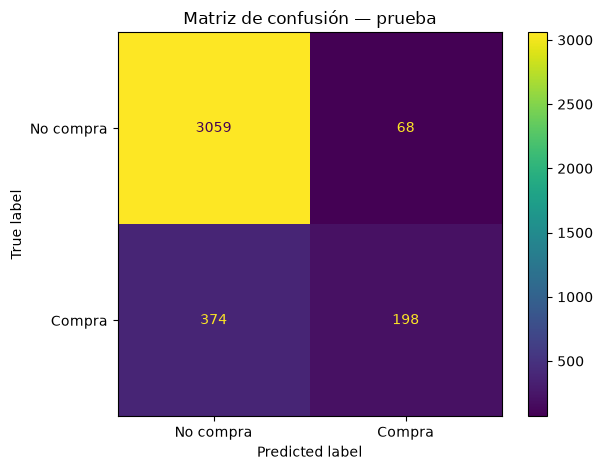

TN=3059 | FP=68 | FN=374 | TP=198


In [11]:
cm = confusion_matrix(y_test, pred_test)
ConfusionMatrixDisplay(cm, display_labels=["No compra","Compra"]).plot(values_format="d")
plt.title("Matriz de confusión — prueba")
plt.tight_layout()
plt.show()

tn, fp, fn, tp = cm.ravel()
print(f"TN={tn} | FP={fp} | FN={fn} | TP={tp}")

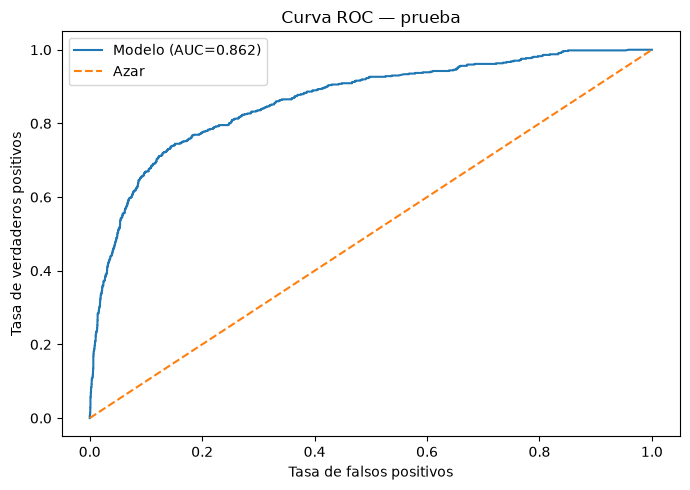

In [12]:
fpr, tpr, _ = roc_curve(y_test, proba_test)
auc_test = roc_auc_score(y_test, proba_test)

plt.figure(figsize=(7,5))
plt.plot(fpr,tpr,label=f"Modelo (AUC={auc_test:.3f})")
plt.plot([0,1],[0,1],"--",label="Azar")
plt.xlabel("Tasa de falsos positivos")
plt.ylabel("Tasa de verdaderos positivos")
plt.title("Curva ROC — prueba")
plt.legend()
plt.tight_layout()
plt.show()

## 11. Baseline mayoritario

Un modelo que siempre prediga “no compra” obtiene una accuracy elevada por el desbalance. Se usa como referencia para evitar conclusiones engañosas.

In [13]:
baseline = np.zeros(len(y_test), dtype=int)
comparacion = pd.DataFrame({
    "Modelo":["Siempre No compra","Regresión logística"],
    "Accuracy":[accuracy_score(y_test,baseline), accuracy_score(y_test,pred_test)],
    "Recall_compra":[0, recall_score(y_test,pred_test,zero_division=0)],
    "F1_compra":[0, f1_score(y_test,pred_test,zero_division=0)],
    "AUC":[.5, auc_test]
})
display(comparacion.round(4))

,Modelo,Accuracy,Recall_compra,F1_compra,AUC
0,Siempre No compra,0.8454,0.0000,0.0000,0.5000
1,Regresión logística,0.8805,0.3462,0.4726,0.8621


## 12. Error de la imputación por mediana

Como los faltantes son artificiales, conocemos los valores verdaderos. Esta ventaja se aprovecha para dejar una línea base de MAE y RMSE que en S3 se comparará con la imputación mediante regresión.

La mediana usada para cada variable se obtiene solo del conjunto de entrenamiento.

In [14]:
errores = []
for variable in VARIABLES_MCAR:
    mediana_train = X_train_full[variable].median()
    idx_train = X_train_full.index[X_train_full[variable].isna()]
    idx_test = X_test_full.index[X_test_full[variable].isna()]
    idx = idx_train.union(idx_test)

    real = valores_originales_mcar.loc[idx, variable]
    imputado = pd.Series(mediana_train, index=idx)

    errores.append({
        "Variable": variable,
        "n_ocultos": len(idx),
        "Mediana_train": mediana_train,
        "MAE_mediana": mean_absolute_error(real, imputado),
        "RMSE_mediana": np.sqrt(mean_squared_error(real, imputado))
    })

tabla_error_mediana = pd.DataFrame(errores)
display(tabla_error_mediana.round(4))

,Variable,n_ocultos,Mediana_train,MAE_mediana,RMSE_mediana
0,ProductRelated_Duration,1480,592.8375,982.1473,1862.2494
1,ExitRates,1480,0.0250,0.0271,0.0472


## 13. Interpretación crítica

Al ejecutar esta versión deben utilizarse **los nuevos resultados MCAR** y no copiar los valores numéricos de la versión anterior.

- Interpretar AUC como discriminación global.
- Revisar especialmente recall y F1 de la clase compra.
- Contrastar accuracy con el baseline mayoritario.
- Confirmar VIF bajos.
- Mantener cautela con `PageValues` por su proximidad al resultado.
- Declarar explícitamente que los faltantes son MCAR artificiales y reproducibles.
- No eliminar outliers automáticamente: S2 no mostró una observación individual dominante.

## 14. Síntesis y conexión con S3

**S1 → F2:** S1 caracterizó el desbalance, asociaciones, correlaciones, outliers y verificó que la base original no tenía faltantes.

**S2 → F2:** S2 validó la estabilidad de relaciones como `BounceRates`–`ExitRates` y `ProductRelated`–`ProductRelated_Duration`. Esas relaciones sustentan la selección de predictores y la elección de las variables del experimento MCAR.

**F2:** se genera 12 % MCAR reproducible en `ExitRates` y `ProductRelated_Duration`, se imputa por mediana sin fuga de información y se ajusta un primer modelo logístico.

### Para Sumativa 3
1. Comparar eliminación, mediana e imputación por regresión lineal múltiple.
2. Comparar MAE/RMSE de las imputaciones contra los valores originales.
3. Construir tres modelos logísticos con criterios de selección distintos.
4. Incorporar ponderación de clase para estudiar mejora del recall.
5. Aplicar bootstrap a coeficientes y OR del mejor modelo.
6. Ampliar diagnósticos: VIF, linealidad en el logit, residuos e influencia.
7. Reajustar el modelo final sobre las tres estrategias de faltantes.
8. Evaluar específicamente el modelo con y sin `PageValues` como análisis de sensibilidad.

Con la estrategia de imputación por mediana, el modelo alcanzó un ROC-AUC de 0,8621 y una accuracy de 88,05 %. Sin embargo, el recall para la clase compra fue de 34,62 %, evidenciando que el umbral de 0,5 mantiene una capacidad limitada para identificar sesiones que efectivamente terminan en compra. Este resultado, consistente con la versión inicial del modelo, fundamenta que en S3 se evalúe ponderación de clases y se comparen distintas especificaciones.

La generación de 12 % de faltantes MCAR y posterior imputación por mediana produjo cambios acotados respecto del modelo ajustado originalmente sobre la base completa: el AUC disminuyó de 0,8666 a 0,8621 y el recall de 35,49 % a 34,62 %. Esto sugiere preliminarmente que las conclusiones generales del modelo se mantienen, aunque la comparación formal entre estrategias de tratamiento de faltantes corresponde a S3.


## 15. Checklist

- [x] Mismo dataset y pregunta de investigación.
- [x] Integración explícita S1/S2.
- [x] Dataset original documentado como completo.
- [x] MCAR 12 % reproducible con semilla 42.
- [x] Valores originales conservados.
- [x] `Revenue` no se altera ni imputa.
- [x] Partición 70/30 estratificada.
- [x] Mediana aprendida solo en train.
- [x] 3–5 predictores conceptuales sustentados.
- [x] Regresión logística, OR e IC.
- [x] VIF.
- [x] Matriz de confusión.
- [x] Accuracy, precision, recall, F1 y AUC.
- [x] Curva ROC.
- [x] Baseline mayoritario.
- [x] MAE/RMSE de imputación simple preparados para S3.
- [x] Mejoras de S3 documentadas.